# Momentum Trading Strategy: S&P 500

Selects S&P 500 stocks with a momentum signal, forms return views with ARIMA, and allocates with Black-Litterman. The portfolio is rebalanced quarterly in a **walk-forward** backtest: every decision on a rebalance date uses only data available on that date. All portfolios, benchmarks included, pay transaction costs.

**Pipeline**

1. Load the S&P 500 constituent snapshots
2. Load and clean the daily data, choosing the right listing when a company has two
3. Build a point-in-time universe
4. Select stocks by momentum (12-1 month return, filtered by RSI)
5. Forecast next-quarter returns with ARIMA, which become the Black-Litterman views
6. Combine the market prior and the views with Black-Litterman (Ledoit-Wolf covariance), then optimise for maximum Sharpe
7. Backtest engine: drifted weights, turnover and transaction costs
8. Walk-forward backtest over 2023
9. Walk-forward backtest over 2010–2023
10. Where the return comes from: each layer of the strategy tested on its own
11. Sensitivity to settings, costs and time period
12. Findings

In [1]:
import warnings
warnings.filterwarnings("ignore")  # statsmodels/pmdarima convergence warnings

import os
import re
import glob
import time
import pickle
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import openpyxl
from joblib import Parallel, delayed
from scipy.optimize import minimize
from sklearn.covariance import LedoitWolf
from pmdarima import auto_arima
from pmdarima.arima import ARIMA

pd.set_option("display.float_format", "{:.4f}".format)

## Configuration

The Phase 3 defaults (Ledoit-Wolf covariance, 10 bps cost per trade) were fixed **before** looking at any Phase 3 results. Section 11 shows how much the results depend on each setting.

In [2]:
DATA_PATH = "tickers/spx_companies_historical_data.csv"
SNAPSHOT_DIR = "tickers"
CACHE_DIR = "cache"          # ARIMA forecasts are cached here (git-ignored); delete to recompute
N_JOBS = -1                  # parallel ARIMA fitting (-1 = all CPU cores)

# Universe and momentum signal
UNIVERSE_SIZE = 50           # largest S&P 500 members by market cap on each rebalance date
MOM_LOOKBACK = 252           # 12-month momentum window (trading days)
MOM_SKIP = 21                # skip the most recent month (short-term reversal)

# Market assumptions (annual)
RISK_FREE = 0.03
MARKET_RISK_PREMIUM = 0.05
COV_LOOKBACK = 756           # 3 years of daily returns for the covariance matrix

# Strategy settings (the baseline; section 11 varies each one)
BASE = dict(
    n_select=25,             # stocks passed to the optimiser
    rsi_max=70,              # exclude overbought stocks
    max_weight=0.20,         # per-stock cap
    tau=0.05,                # Black-Litterman prior uncertainty
    cov="ledoit_wolf",       # "ledoit_wolf" or "sample"
    use_views=True,          # False = Black-Litterman prior only (no ARIMA)
)
COST_BPS = 10                # cost per unit traded (per side), charged to every portfolio

TEST_START, TEST_END = "2023-01-01", "2023-12-31"
LONG_START, LONG_END = "2010-01-01", "2023-12-31"

## 1. S&P 500 constituent snapshots

There are 168 quarterly snapshots, 2000–2023. Each lists the index members on that date with their exact Bloomberg listing (for example `AAPL UW Equity`). They are used twice: to pick the correct listing during cleaning, and to build a universe free of survivorship bias.

In [3]:
def parse_snapshot_date(filename):
    # Some filenames end in '20221' (a trailing copy suffix), so only the first 4 digits are the year
    match = re.search(r"as of (\w{3} \d{2} \d{4})", filename)
    if not match:
        raise ValueError(f"Unable to parse date from filename: {filename}")
    return pd.Timestamp(datetime.strptime(match.group(1), "%b %d %Y"))


def load_snapshots(folder):
    snapshots = {}
    for path in glob.glob(os.path.join(folder, "*.xlsx")):
        sheet = openpyxl.load_workbook(path, read_only=True, data_only=True).active
        rows = list(sheet.iter_rows(values_only=True))
        col = rows[0].index("Ticker")
        snapshots[parse_snapshot_date(os.path.basename(path))] = {r[col] for r in rows[1:] if r[col]}
    return dict(sorted(snapshots.items()))


snapshot_listings = load_snapshots(SNAPSHOT_DIR)                      # date -> {'AAPL UW Equity', ...}
snapshots = {d: {l.split(" ")[0] for l in s} for d, s in snapshot_listings.items()}  # date -> {'AAPL', ...}
snapshot_dates = np.array(list(snapshots), dtype="datetime64[ns]")
print(f"{len(snapshots)} snapshots, {min(snapshots).date()} to {max(snapshots).date()}")

168 snapshots, 1999-12-31 to 2023-12-31


## 2. Load and clean the data

* 28% of raw rows are blank (weekends and holidays). They are dropped *before* de-duplicating, so a blank row can never replace a real price.
* Tickers are reduced to the base symbol (`AAPL UW Equity` → `AAPL`). Bloomberg already gives delisted companies unique codes (such as `1431816D`), so two different companies never share a base symbol here; the only rename in the snapshots is Boston Properties → BXP Inc.
* About 136 companies have two listings, usually from an exchange move. On dates where both have prices, the listing **named in that date's snapshot** is kept; otherwise the listing with the longer history is kept.

Dividend data is not available: `DVD_YLD_IND` is empty in every row. All returns are therefore **price returns**.

In [4]:
raw = pd.read_csv(DATA_PATH, parse_dates=["date"])
print(f"Raw rows: {len(raw):,}  |  listings: {raw['ticker'].nunique():,}  |  "
      f"dividend-yield coverage: {raw['DVD_YLD_IND'].notna().mean():.1%}")

df = raw.dropna(subset=["PX_LAST"]).copy()
df["listing"] = df["ticker"]
df["ticker"] = df["listing"].str.split(" ").str[0]          # 'AAPL UW Equity' -> 'AAPL'

# Was this listing named in the most recent snapshot on or before this date?
pos = np.searchsorted(snapshot_dates, df["date"].values, side="right") - 1
df["snapshot"] = snapshot_dates[np.clip(pos, 0, None)]
named = pd.DataFrame([(d, l) for d, ls in snapshot_listings.items() for l in ls], columns=["snapshot", "listing"])
named["in_snapshot"] = True
df = df.merge(named, on=["snapshot", "listing"], how="left")
df["in_snapshot"] = df["in_snapshot"].fillna(False).astype(bool)
df["history"] = df.groupby("listing")["date"].transform("size")

dup = df[df.duplicated(["ticker", "date"], keep=False)]
spread = dup.groupby(["ticker", "date"])["PX_LAST"].agg(lambda s: s.max() / s.min() - 1)
print(f"Company-dates with two listings: {len(spread):,}; listings disagree by >0.5% on {(spread > 0.005).sum():,}")

df = (df.sort_values(["ticker", "date", "in_snapshot", "history"], ascending=[True, True, False, False])
        .drop_duplicates(["ticker", "date"]))
print(f"Clean rows: {len(df):,}  |  companies: {df['ticker'].nunique():,}  |  "
      f"{df['date'].min().date()} to {df['date'].max().date()}")

# Wide tables: one row per trading day, one column per ticker
prices = df.pivot(index="date", columns="ticker", values="PX_LAST")
mcap = df.pivot(index="date", columns="ticker", values="CUR_MKT_CAP")
del raw, df, dup
prices.shape

Raw rows: 6,783,534  |  listings: 1,206  |  dividend-yield coverage: 0.0%
Company-dates with two listings: 421,052; listings disagree by >0.5% on 740
Clean rows: 4,420,882  |  companies: 1,057  |  2000-01-03 to 2023-12-29


(6037, 1057)

## 3. Point-in-time universe and rebalance dates

On each rebalance date the universe is the largest members of the S&P 500 **as listed in the most recent snapshot on or before that date**, ranked by their market cap on that date. The portfolio is formed on the last trading day of each quarter and held for the following quarter.

In [5]:
def constituents(date):
    latest = max(d for d in snapshots if d <= date)
    return snapshots[latest]


def universe(date, size=UNIVERSE_SIZE):
    # Largest index members with a price on `date`; returns market caps, largest first
    members = [t for t in constituents(date) if t in prices.columns]
    caps = mcap.loc[:date, members].iloc[-5:].ffill().iloc[-1]
    caps = caps[prices.loc[date, members].notna()].dropna()
    return caps.sort_values(ascending=False).head(size)


def formation_dates(start, end):
    # Last trading day of each quarter, from the quarter before `start` up to (not including) the end
    idx = prices.index
    quarter_ends = pd.Series(idx, index=idx).groupby(idx.to_period("Q")).max()
    last_day = prices.loc[:end].index[-1]
    first_quarter = pd.Timestamp(start).to_period("Q") - 1
    return [d for q, d in quarter_ends.items() if q >= first_quarter and d < last_day]


test_dates = formation_dates(TEST_START, TEST_END)
long_dates = formation_dates(LONG_START, LONG_END)
FIRST = test_dates[0]
print("2023 formation dates:", [str(d.date()) for d in test_dates])
print(f"2010–2023: {len(long_dates)} formation dates, {long_dates[0].date()} to {long_dates[-1].date()}")

uni = universe(FIRST)
print(f"\nUniverse on {FIRST.date()}: {len(uni)} stocks, largest: {', '.join(uni.index[:10])}")

2023 formation dates: ['2022-12-30', '2023-03-31', '2023-06-30', '2023-09-29']
2010–2023: 56 formation dates, 2009-12-31 to 2023-09-29

Universe on 2022-12-30: 50 stocks, largest: AAPL, MSFT, GOOGL, GOOG, AMZN, BRK/B, UNH, JNJ, XOM, V


## 4. Momentum selection

* **12-1 momentum:** return from 12 months ago to 1 month ago. The latest month is skipped because very recent winners tend to reverse briefly.
* **RSI (14-day, Wilder smoothing):** stocks above `rsi_max` (70) are treated as overbought and excluded.
* **MACD histogram (12/26/9):** reported to confirm the trend (positive = MACD above its signal line).

The `n_select` (25) stocks with the highest momentum that pass the RSI filter go on to the optimiser.

In [6]:
def rsi(series, n=14):
    delta = series.diff()
    gain = delta.clip(lower=0).ewm(alpha=1 / n, adjust=False).mean()
    loss = (-delta.clip(upper=0)).ewm(alpha=1 / n, adjust=False).mean()
    return 100 - 100 / (1 + gain / loss)


def macd(series):
    line = series.ewm(span=12, adjust=False).mean() - series.ewm(span=26, adjust=False).mean()
    signal = line.ewm(span=9, adjust=False).mean()
    return line, signal


def momentum_signals(date, tickers):
    window = prices.loc[:date, tickers].iloc[-(MOM_LOOKBACK + 300):]
    rows = {}
    for t in tickers:
        s = window[t].dropna()
        if len(s) <= MOM_LOOKBACK:
            continue  # not enough history
        line, signal = macd(s)
        rows[t] = {
            "momentum_12_1": s.iloc[-1 - MOM_SKIP] / s.iloc[-1 - MOM_LOOKBACK] - 1,
            "rsi": rsi(s).iloc[-1],
            "macd_hist": (line - signal).iloc[-1],
        }
    return pd.DataFrame(rows).T


def select_stocks(signals, n_select, rsi_max):
    eligible = signals[signals["rsi"] < rsi_max]
    return eligible.sort_values("momentum_12_1", ascending=False).head(n_select)


selected = select_stocks(momentum_signals(FIRST, list(uni.index)), BASE["n_select"], BASE["rsi_max"])
print(f"Selected {len(selected)} stocks on {FIRST.date()}")
selected

Selected 25 stocks on 2022-12-30


,momentum_12_1,rsi,macd_hist
XOM,0.8316,56.4777,0.4864
CVX,0.5610,55.9044,0.9031
MRK,0.4275,61.0484,-0.3482
LLY,0.3384,52.9763,-0.2512
TMUS,0.3000,41.7625,-0.2730
BMY,0.2841,28.7816,-0.4877
ABBV,0.1858,53.2152,-0.6677
RTX,0.1506,61.4029,-0.0714
UNH,0.0859,49.1247,-0.3640
KO,0.0822,55.4859,-0.1137


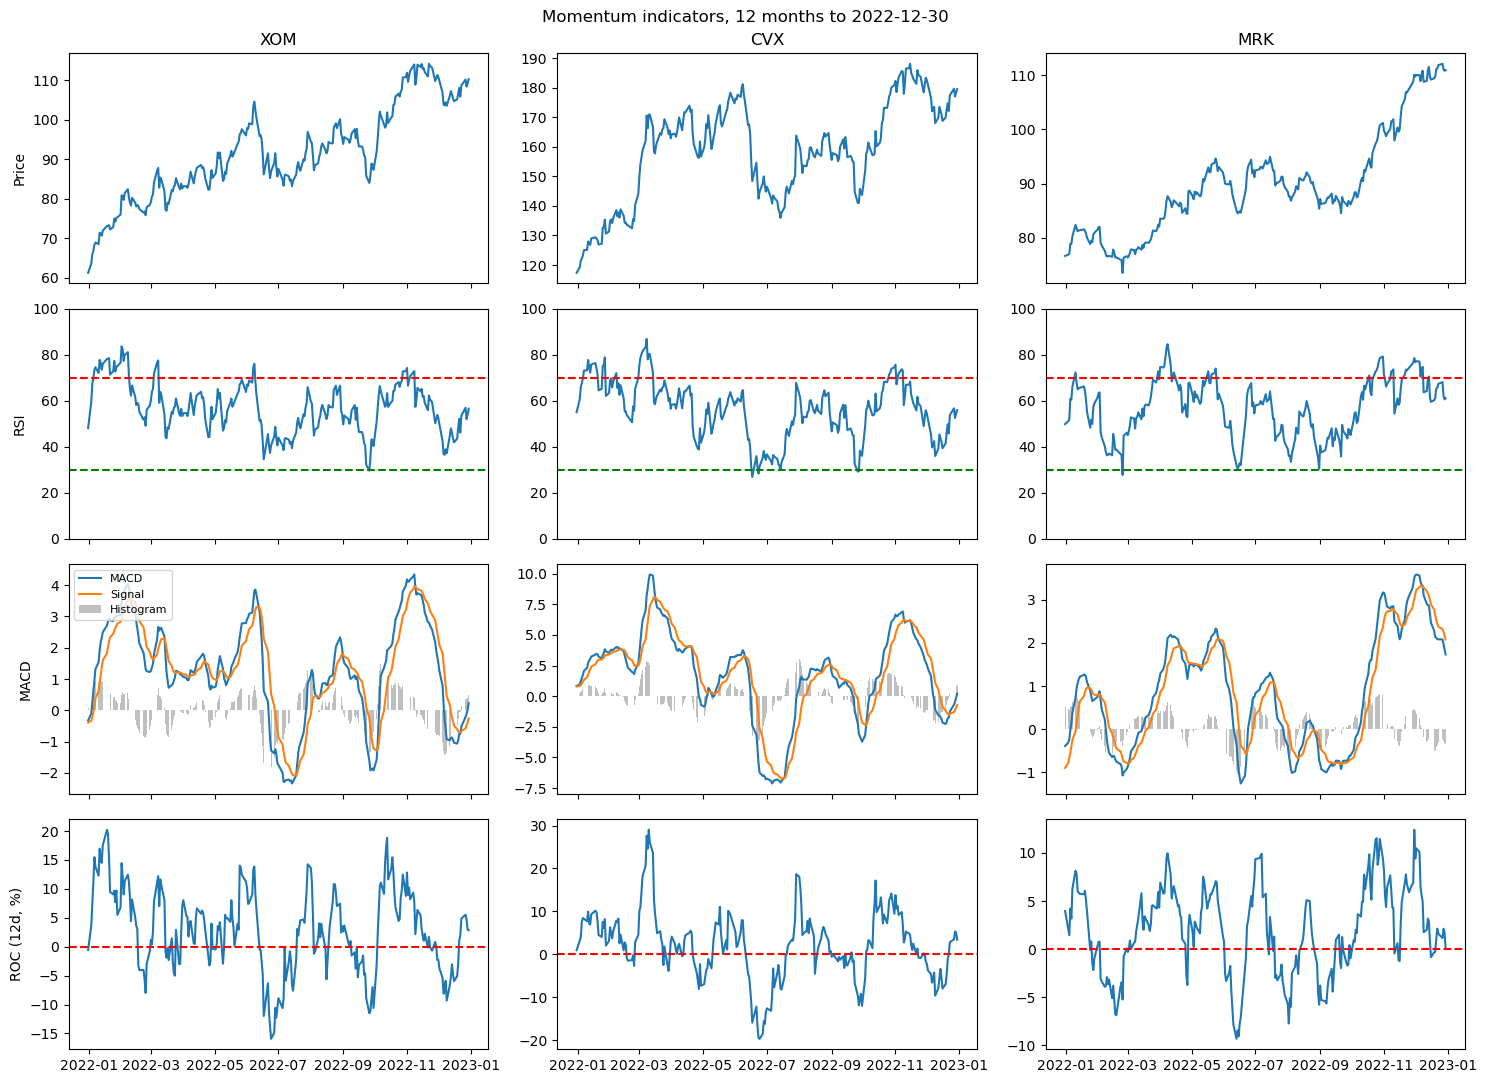

In [7]:
# Momentum indicators for the three strongest selected stocks (last 12 months to the formation date)
show = selected.index[:3]
fig, axes = plt.subplots(4, len(show), figsize=(15, 11), sharex="col")
for j, t in enumerate(show):
    s = prices.loc[:FIRST, t].dropna()
    line, signal = macd(s)
    roc = s.pct_change(12) * 100
    r = rsi(s)
    w = s.index[-MOM_LOOKBACK:]
    axes[0, j].plot(w, s[w]); axes[0, j].set_title(t)
    axes[1, j].plot(w, r[w]); axes[1, j].axhline(70, color="r", ls="--"); axes[1, j].axhline(30, color="g", ls="--"); axes[1, j].set_ylim(0, 100)
    axes[2, j].plot(w, line[w], label="MACD"); axes[2, j].plot(w, signal[w], label="Signal")
    axes[2, j].bar(w, (line - signal)[w], color="grey", alpha=0.5, label="Histogram")
    axes[3, j].plot(w, roc[w]); axes[3, j].axhline(0, color="r", ls="--")
for ax, label in zip(axes[:, 0], ["Price", "RSI", "MACD", "ROC (12d, %)"]):
    ax.set_ylabel(label)
axes[2, 0].legend(loc="upper left", fontsize=8)
fig.suptitle(f"Momentum indicators, 12 months to {FIRST.date()}")
plt.tight_layout()
plt.show()

## 5. ARIMA return views

For each stock, `auto_arima` chooses an ARIMA order for its **quarterly log returns** up to the formation date, with no seasonal term. That order is then refitted **with an intercept forced on**: otherwise the stepwise search sometimes drops the intercept, and a (0,0,0) model forecasts exactly 0 instead of the stock's average return. The one-quarter-ahead forecast, annualised, becomes the stock's view in Black-Litterman.

Forecasts are computed for every universe stock on every rebalance date, in parallel, and cached in `cache/`, so the many backtest variants below reuse them.

In [8]:
def quarterly_log_returns(date, ticker):
    q = prices.loc[:date, ticker].dropna().resample(pd.offsets.QuarterEnd()).last()
    return np.log(q).diff().dropna()


def fit_arima(q):
    import warnings
    warnings.filterwarnings("ignore")
    order = auto_arima(q, seasonal=False, max_p=3, max_q=3,
                       suppress_warnings=True, error_action="ignore").order
    model = ARIMA(order=order, with_intercept=True, suppress_warnings=True).fit(q)
    fc, ci = model.predict(1, return_conf_int=True)
    fc = float(np.asarray(fc)[0])
    return {"view_annual": np.exp(4 * fc) - 1, "fc_quarter": fc,
            "ci_low": float(ci[0][0]), "ci_high": float(ci[0][1]), "order": order}


def arima_views(jobs):
    # jobs: list of (date, ticker). Returns {(date, ticker): result}, using and updating the disk cache.
    os.makedirs(CACHE_DIR, exist_ok=True)
    path = os.path.join(CACHE_DIR, "arima_views.pkl")
    cache = pickle.load(open(path, "rb")) if os.path.exists(path) else {}
    todo = [j for j in dict.fromkeys(jobs) if j not in cache]
    if todo:
        t0 = time.time()
        results = Parallel(n_jobs=N_JOBS)(delayed(fit_arima)(quarterly_log_returns(d, t)) for d, t in todo)
        cache.update(zip(todo, results))
        pickle.dump(cache, open(path, "wb"))
        print(f"Fitted {len(todo):,} ARIMA models in {time.time() - t0:.0f}s ({len(cache):,} cached)")
    return {j: cache[j] for j in jobs}


views = pd.DataFrame({t: v for (_, t), v in arima_views([(FIRST, t) for t in selected.index]).items()}).T
views[["view_annual", "fc_quarter", "ci_low", "ci_high"]] = views[["view_annual", "fc_quarter", "ci_low", "ci_high"]].astype(float)
views

,view_annual,fc_quarter,ci_low,ci_high,order
XOM,0.0469,0.0115,-0.2310,0.2539,"(0, 0, 0)"
CVX,-0.0827,-0.0216,-0.2514,0.2082,"(1, 0, 0)"
MRK,0.0305,0.0075,-0.2127,0.2277,"(0, 0, 0)"
LLY,0.1606,0.0372,-0.1589,0.2334,"(3, 1, 1)"
TMUS,0.0498,0.0121,-0.3593,0.3835,"(0, 0, 0)"
BMY,0.0119,0.0030,-0.2283,0.2342,"(0, 0, 0)"
ABBV,-0.0472,-0.0121,-0.2241,0.2000,"(1, 0, 0)"
RTX,-0.0741,-0.0192,-0.2660,0.2275,"(0, 0, 1)"
UNH,0.2062,0.0469,-0.1981,0.2918,"(0, 0, 0)"
KO,0.0109,0.0027,-0.1511,0.1565,"(3, 0, 0)"


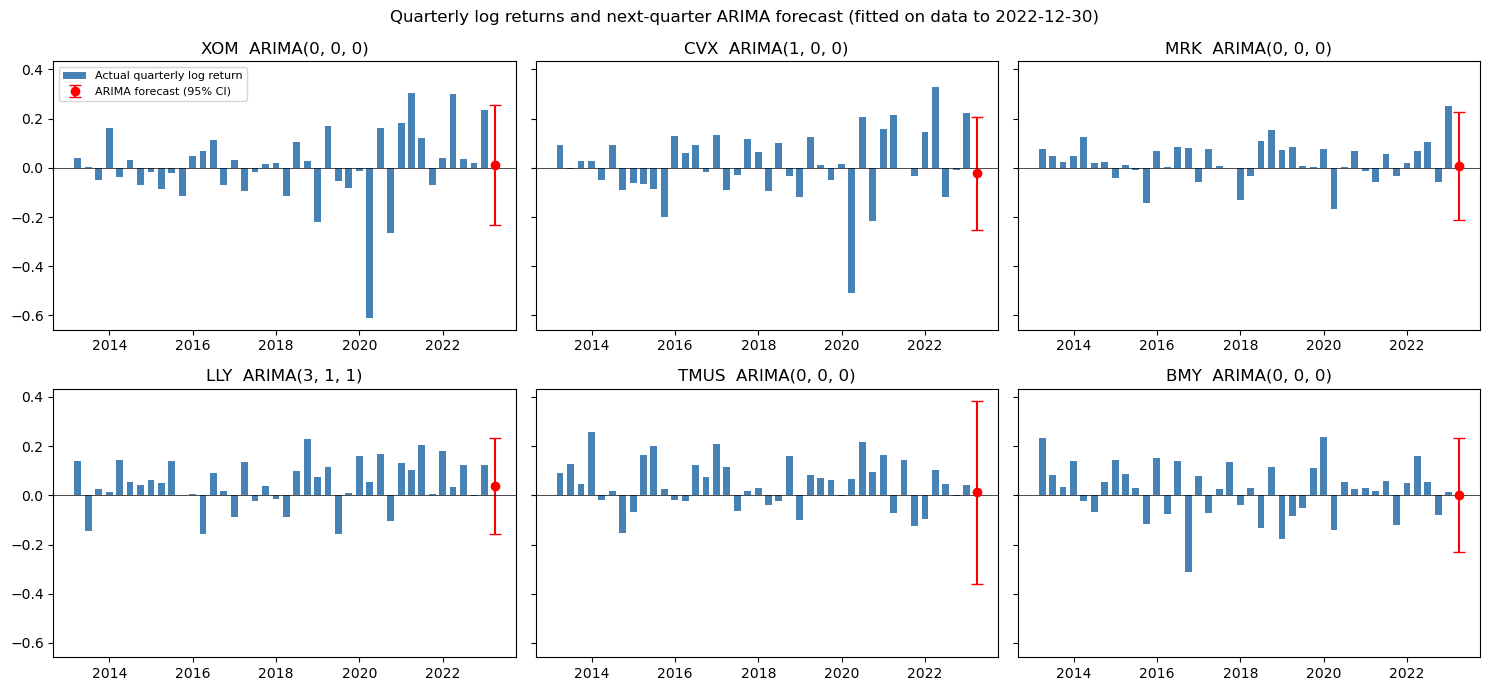

In [9]:
# History and forecast for six of the selected stocks
show = selected.index[:6]
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharey=True)
for ax, t in zip(axes.flat, show):
    q = quarterly_log_returns(FIRST, t).iloc[-40:]
    nxt = q.index[-1] + pd.offsets.QuarterEnd()
    ax.bar(q.index, q.values, width=60, color="steelblue", label="Actual quarterly log return")
    v = views.loc[t]
    ax.errorbar([nxt], [v.fc_quarter], yerr=[[v.fc_quarter - v.ci_low], [v.ci_high - v.fc_quarter]],
                fmt="o", color="red", capsize=4, label="ARIMA forecast (95% CI)")
    ax.axhline(0, color="black", lw=0.5)
    ax.set_title(f"{t}  ARIMA{v.order}")
axes[0, 0].legend(fontsize=8)
fig.suptitle(f"Quarterly log returns and next-quarter ARIMA forecast (fitted on data to {FIRST.date()})")
plt.tight_layout()
plt.show()

## 6. Black-Litterman allocation

All quantities are **annual excess returns** over the risk-free rate.

* Covariance: $\Sigma$ = covariance of 3 years of daily returns × 252, estimated with **Ledoit-Wolf shrinkage** by default. The plain sample covariance of 25 stocks is noisy, and max-Sharpe optimisation amplifies that noise.
* Risk aversion: $\delta = \text{MRP} / (w_{mkt}^\top \Sigma\, w_{mkt})$
* Prior (implied returns): $\pi = \delta\, \Sigma\, w_{mkt}$, where $w_{mkt}$ are market-cap weights
* Views: one absolute view per stock ($P = I$), $Q$ = ARIMA forecast − risk-free rate, with uncertainty $\Omega = \text{diag}(P\, \tau\Sigma\, P^\top)$ (He & Litterman)
* Posterior mean: $\mu_{BL} = \pi + \tau\Sigma P^\top (P\,\tau\Sigma\,P^\top + \Omega)^{-1}(Q - P\pi)$
* Posterior covariance: $\Sigma_{BL} = \Sigma + \left[(\tau\Sigma)^{-1} + P^\top\Omega^{-1}P\right]^{-1}$
* Without views (`use_views=False`): $\mu = \pi$ and $\Sigma_{BL} = (1+\tau)\Sigma$

Weights maximise $w^\top\mu_{BL} / \sqrt{w^\top\Sigma_{BL}w}$, long-only, fully invested, each at most `max_weight`. If no stock has a positive expected excess return, the minimum-variance portfolio is used instead. Every vector stays labelled by ticker.

In [10]:
def covariance(rets, method):
    if method == "ledoit_wolf":
        clean = rets.dropna()
        return LedoitWolf().fit(clean.values).covariance_ * 252
    return rets.cov().values * 252


def black_litterman(date, tickers, caps, views, tau=0.05, max_weight=0.20,
                    cov="ledoit_wolf", use_views=True):
    rets = prices.loc[:date, tickers].iloc[-COV_LOOKBACK:].pct_change(fill_method=None).iloc[1:]
    tickers = list(rets.columns[rets.notna().mean() > 0.8])   # need 80% of the covariance window
    rets = rets[tickers]

    Sigma = covariance(rets, cov)
    w_mkt = (caps[tickers] / caps[tickers].sum()).values
    delta = MARKET_RISK_PREMIUM / (w_mkt @ Sigma @ w_mkt)
    pi = delta * Sigma @ w_mkt
    Q = np.array([views[t] for t in tickers]) - RISK_FREE

    if use_views:
        P = np.eye(len(tickers))
        tS = tau * Sigma
        Omega = np.diag(np.diag(P @ tS @ P.T))
        mu = pi + tS @ P.T @ np.linalg.solve(P @ tS @ P.T + Omega, Q - P @ pi)
        Sigma_bl = Sigma + np.linalg.inv(np.linalg.inv(tS) + P.T @ np.linalg.inv(Omega) @ P)
    else:
        mu, Sigma_bl = pi, (1 + tau) * Sigma

    n = len(tickers)
    if mu.max() > 0:
        objective = lambda w: -(w @ mu) / np.sqrt(w @ Sigma_bl @ w)
    else:
        objective = lambda w: w @ Sigma_bl @ w
    result = minimize(objective, np.full(n, 1 / n), method="SLSQP",
                      bounds=[(0, max(max_weight, 1 / n))] * n,
                      constraints=({"type": "eq", "fun": lambda w: w.sum() - 1},))
    weights = np.clip(result.x, 0, None)
    weights /= weights.sum()

    return pd.DataFrame({
        "weight": weights, "w_mkt": w_mkt, "prior_pi": pi, "view_Q": Q,
        "posterior_mu": mu, "volatility": np.sqrt(np.diag(Sigma_bl)),
    }, index=tickers)


bl = black_litterman(FIRST, list(selected.index), uni, views["view_annual"],
                     **{k: BASE[k] for k in ("tau", "max_weight", "cov", "use_views")})
held = bl[bl["weight"] > 0.001].sort_values("weight", ascending=False)
print(f"Holding {len(held)} of {len(bl)} stocks on {FIRST.date()}")
held

Holding 6 of 25 stocks on 2022-12-30


,weight,w_mkt,prior_pi,view_Q,posterior_mu,volatility
V,0.2000,0.0604,0.0612,0.1619,0.1035,0.3363
MA,0.2000,0.0460,0.0673,0.2664,0.1237,0.3769
PG,0.2000,0.0494,0.0383,0.2640,0.0927,0.2463
UNH,0.1838,0.0682,0.0582,0.1762,0.0789,0.3322
LLY,0.1492,0.0478,0.0447,0.1306,0.0620,0.3470
COST,0.0670,0.0279,0.0368,0.0223,0.0446,0.2744


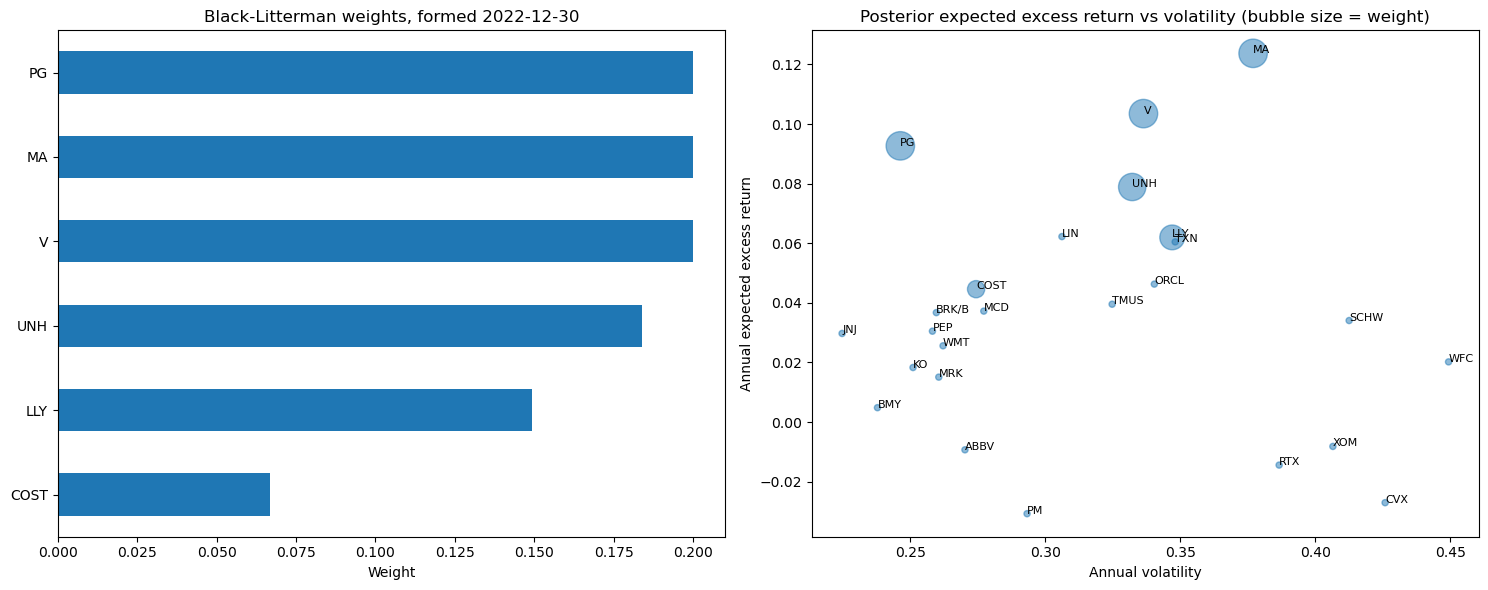

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
held["weight"].sort_values().plot(kind="barh", ax=ax1)
ax1.set_title(f"Black-Litterman weights, formed {FIRST.date()}")
ax1.set_xlabel("Weight")

ax2.scatter(bl["volatility"], bl["posterior_mu"], s=20 + bl["weight"] * 2000, alpha=0.5)
for t, row in bl.iterrows():
    ax2.annotate(t, (row["volatility"], row["posterior_mu"]), fontsize=8)
ax2.set_title("Posterior expected excess return vs volatility (bubble size = weight)")
ax2.set_xlabel("Annual volatility")
ax2.set_ylabel("Annual expected excess return")
plt.tight_layout()
plt.show()

## 7. Backtest engine

**Precompute.** For every rebalance date from 2010 to 2023, the universe, momentum signals and ARIMA forecasts for all 50 universe stocks are computed once. Any variant of the strategy can then be backtested in seconds.

**Simulation.** On each formation date the target weights are set. Between rebalances the holdings **drift** with prices (buy-and-hold); a stock that stops trading keeps its last price.

**Costs.** At each rebalance, turnover = Σ|target weight − drifted weight|, and the portfolio pays `COST_BPS` per unit traded. The first purchase is charged too.

**Benchmarks** (same rebalancing and costs):
* **Equal-weight top 50:** the same universe, equally weighted
* **Cap-weight top 50:** the same universe, weighted by market cap
* **Cap-weight S&P 500:** all index members by market cap, a proxy for the S&P 500 price index

**Statistics.** Alongside return, volatility, Sharpe and drawdown, each portfolio is compared with the S&P 500 proxy: annual excess return, tracking error, information ratio (IR = excess return ÷ tracking error), and a t-statistic (IR × √years). A t-statistic below about 2 means the difference could easily be luck.

In [12]:
t0 = time.time()
context = {}
for f in long_dates:
    u = universe(f)
    sp = universe(f, size=10_000)
    context[f] = {"universe": u, "sp500": sp, "signals": momentum_signals(f, list(u.index))}
all_views = arima_views([(f, t) for f in long_dates for t in context[f]["signals"].index])
for f in long_dates:
    context[f]["views"] = pd.Series({t: all_views[(f, t)]["view_annual"] for t in context[f]["signals"].index})
print(f"Precomputed {len(context)} rebalance dates in {time.time() - t0:.0f}s")

Precomputed 56 rebalance dates in 2s


In [13]:
def strategy(n_select=25, rsi_max=70, max_weight=0.20, tau=0.05, cov="ledoit_wolf",
             use_views=True, weighting="black_litterman"):
    # Returns a function: formation date -> target weights
    def weights(f):
        c = context[f]
        sel = select_stocks(c["signals"], n_select, rsi_max)
        if weighting == "equal":
            return pd.Series(1 / len(sel), index=sel.index)
        bl = black_litterman(f, list(sel.index), c["universe"], c["views"],
                             tau=tau, max_weight=max_weight, cov=cov, use_views=use_views)
        return bl["weight"]
    return weights


BENCHMARKS = {
    "Equal-weight top 50": lambda f: pd.Series(1 / len(context[f]["universe"]), index=context[f]["universe"].index),
    "Cap-weight top 50": lambda f: context[f]["universe"] / context[f]["universe"].sum(),
    "Cap-weight S&P 500": lambda f: context[f]["sp500"] / context[f]["sp500"].sum(),
}


def simulate(weight_fn, dates, end, cost_bps=COST_BPS):
    ends = dates[1:] + [prices.loc[:end].index[-1]]
    level, held, pieces, traded, log = 1.0, None, [], [], {}
    for f, f_next in zip(dates, ends):
        target = weight_fn(f)
        drifted = held / held.sum() if held is not None else pd.Series(dtype=float)
        names = target.index.union(drifted.index)
        turnover = (target.reindex(names, fill_value=0) - drifted.reindex(names, fill_value=0)).abs().sum()
        level *= 1 - cost_bps / 1e4 * turnover
        if held is not None:
            traded.append(turnover)
        p = prices.loc[f:f_next, target.index].ffill()
        values = (p / p.iloc[0]).mul(target * level, axis=1)
        curve = values.sum(axis=1)
        pieces.append(curve if not pieces else curve.iloc[1:])
        level, held = curve.iloc[-1], values.iloc[-1]
        log[f] = target
    curve = pd.concat(pieces)
    years = (curve.index[-1] - curve.index[0]).days / 365.25
    curve.attrs["turnover"] = sum(traded) / years
    return curve, pd.DataFrame(log).fillna(0)


def performance(curves, benchmark="Cap-weight S&P 500"):
    bench = curves[benchmark].pct_change().dropna()
    out = {}
    for k in curves:
        v = curves[k]
        r = v.pct_change().dropna()
        years = (v.index[-1] - v.index[0]).days / 365.25
        vol = r.std() * np.sqrt(252)
        active = r - bench
        te = active.std() * np.sqrt(252)
        ir = active.mean() * 252 / te if te > 0 else np.nan
        out[k] = {
            "CAGR": (v.iloc[-1] / v.iloc[0]) ** (1 / years) - 1,
            "Volatility": vol,
            "Sharpe": (r.mean() * 252 - RISK_FREE) / vol,
            "Max drawdown": (v / v.cummax() - 1).min(),
            "Turnover / yr": v.attrs.get("turnover", np.nan),
            "Excess vs S&P": active.mean() * 252,
            "Tracking error": te,
            "IR": ir,
            "t-stat": ir * np.sqrt(years) if te > 0 else np.nan,
        }
    return pd.DataFrame(out).T


def show_performance(perf):
    pct = [c for c in ["CAGR", "Volatility", "Max drawdown", "Turnover / yr", "Excess vs S&P", "Tracking error"] if c in perf]
    num = [c for c in ["Sharpe", "IR", "t-stat"] if c in perf]
    return perf.style.format("{:.1%}", subset=pct).format("{:.2f}", subset=num)


def run(portfolios, dates, end):
    # Curves are kept as a dict of Series: each carries its turnover in .attrs
    sims = {name: simulate(fn, dates, end) for name, fn in portfolios.items()}
    curves = {name: s[0] for name, s in sims.items()}
    logs = {name: s[1] for name, s in sims.items()}
    return curves, logs


STRATEGY = {"Strategy": strategy(**BASE)}

## 8. Walk-forward backtest: 2023

Four rebalances, after costs.

In [14]:
curves_2023, logs_2023 = run({**STRATEGY, **BENCHMARKS}, test_dates, TEST_END)
show_performance(performance(curves_2023))

,CAGR,Volatility,Sharpe,Max drawdown,Turnover / yr,Excess vs S&P,Tracking error,IR,t-stat
Strategy,11.5%,13.3%,0.66,-9.1%,453.1%,-12.0%,9.9%,-1.21,-1.21
Equal-weight top 50,23.1%,12.4%,1.50,-9.7%,56.7%,-2.2%,2.7%,-0.83,-0.83
Cap-weight top 50,37.2%,15.0%,2.00,-8.7%,12.0%,9.0%,4.5%,1.99,1.99
Cap-weight S&P 500,25.7%,13.3%,1.56,-10.0%,2.7%,0.0%,0.0%,nan,nan


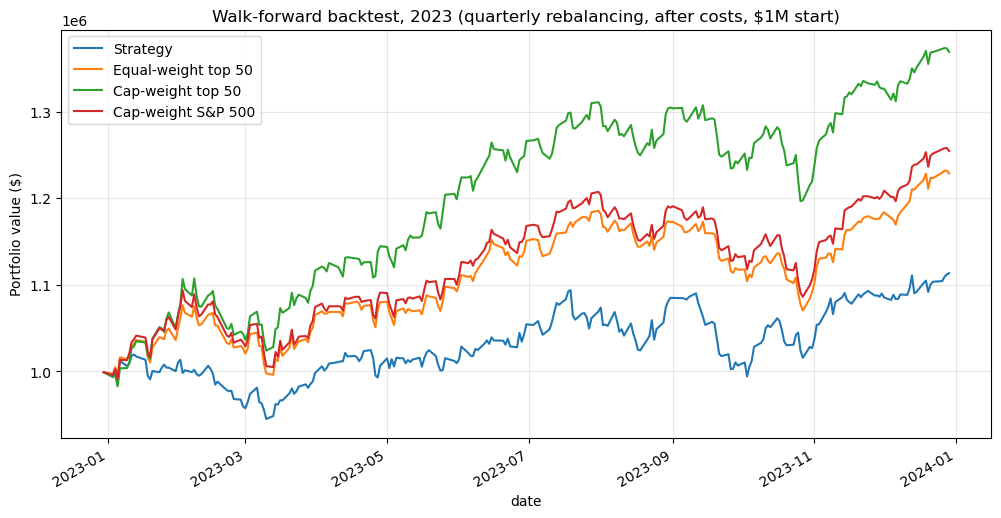

,2022-12-30,2023-03-31,2023-06-30,2023-09-29
MA,20.0%,3.7%,20.0%,6.6%
V,20.0%,2.2%,20.0%,15.4%
PG,20.0%,0.0%,0.0%,0.0%
UNH,18.4%,7.5%,0.0%,0.0%
LLY,14.9%,20.0%,0.0%,20.0%
COST,6.7%,0.0%,0.0%,0.0%
LIN,0.0%,0.0%,0.0%,0.8%
MRK,0.0%,0.0%,0.0%,20.0%
KO,0.0%,9.7%,0.0%,0.0%
TXN,0.0%,20.0%,0.0%,0.0%


In [15]:
START_VALUE = 1_000_000
(pd.DataFrame(curves_2023) * START_VALUE).plot(
    figsize=(12, 6), title="Walk-forward backtest, 2023 (quarterly rebalancing, after costs, $1M start)")
plt.ylabel("Portfolio value ($)")
plt.grid(alpha=0.3)
plt.show()

alloc = logs_2023["Strategy"]
alloc = alloc.loc[(alloc > 0.001).any(axis=1)]
alloc.columns = [d.date() for d in alloc.columns]
alloc.sort_values(alloc.columns[0], ascending=False).style.format("{:.1%}")

## 9. Walk-forward backtest: 2010–2023

56 rebalances, after costs.

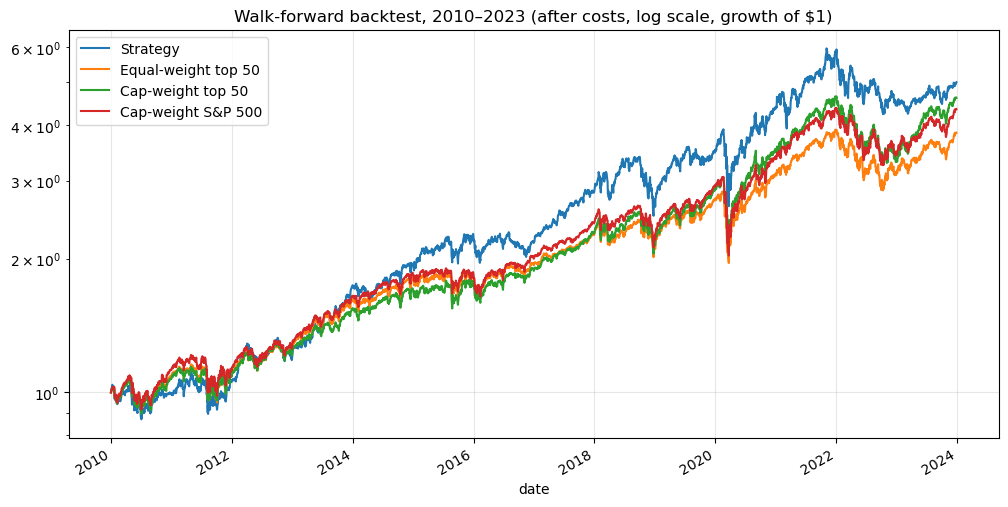

,CAGR,Volatility,Sharpe,Max drawdown,Turnover / yr,Excess vs S&P,Tracking error,IR,t-stat
Strategy,12.2%,20.4%,0.52,-33.0%,453.2%,1.6%,10.2%,0.15,0.58
Equal-weight top 50,10.1%,16.8%,0.48,-31.1%,67.1%,-1.0%,2.6%,-0.39,-1.46
Cap-weight top 50,11.5%,17.9%,0.53,-30.0%,21.9%,0.5%,3.6%,0.14,0.51
Cap-weight S&P 500,11.1%,17.5%,0.52,-33.6%,7.9%,0.0%,0.0%,nan,nan


In [16]:
curves_long, logs_long = run({**STRATEGY, **BENCHMARKS}, long_dates, LONG_END)
perf_long = performance(curves_long)

pd.DataFrame(curves_long).plot(figsize=(12, 6), logy=True,
                               title="Walk-forward backtest, 2010–2023 (after costs, log scale, growth of $1)")
plt.grid(alpha=0.3)
plt.show()
show_performance(perf_long)

In [17]:
yearly = pd.DataFrame(curves_long).resample(pd.offsets.YearEnd()).last().pct_change().dropna()
yearly.index = yearly.index.year
yearly["Strategy − S&P"] = yearly["Strategy"] - yearly["Cap-weight S&P 500"]
print(f"Strategy beat the S&P 500 proxy in {(yearly['Strategy − S&P'] > 0).sum()} of {len(yearly)} years")
yearly.style.format("{:.1%}")

Strategy beat the S&P 500 proxy in 8 of 14 years


,Strategy,Equal-weight top 50,Cap-weight top 50,Cap-weight S&P 500,Strategy − S&P
date,,,,,
2010,-0.8%,8.6%,7.2%,12.3%,-13.2%
2011,6.6%,0.5%,1.6%,-0.0%,6.6%
2012,14.0%,14.5%,12.9%,13.4%,0.6%
2013,44.8%,29.7%,26.0%,29.7%,15.1%
2014,10.2%,10.3%,9.1%,11.0%,-0.9%
2015,16.6%,2.1%,3.8%,0.1%,16.4%
2016,-3.0%,6.0%,7.2%,9.0%,-12.0%
2017,29.9%,17.0%,21.3%,20.1%,9.8%
2018,-3.5%,-4.5%,-3.3%,-5.9%,2.4%


## 10. Where does the return come from?

The strategy stacks three layers on the universe. Adding them one at a time shows which, if any, adds value:

1. **Universe, equal-weight:** the 50 largest S&P 500 stocks
2. **+ Momentum selection, equal-weight:** the top 25 by momentum, equally weighted
3. **+ Black-Litterman, no views:** the same 25 stocks, max-Sharpe on the market-implied prior only
4. **+ ARIMA views:** the full strategy

In [18]:
LAYERS = {
    "1. Universe, equal-weight": BENCHMARKS["Equal-weight top 50"],
    "2. + Momentum, equal-weight": strategy(**{**BASE, "weighting": "equal"}),
    "3. + Black-Litterman, no views": strategy(**{**BASE, "use_views": False}),
    "4. + ARIMA views (strategy)": STRATEGY["Strategy"],
    "Cap-weight S&P 500": BENCHMARKS["Cap-weight S&P 500"],
}
curves_layers, _ = run(LAYERS, long_dates, LONG_END)
perf_layers = performance(curves_layers)
show_performance(perf_layers)

,CAGR,Volatility,Sharpe,Max drawdown,Turnover / yr,Excess vs S&P,Tracking error,IR,t-stat
"1. Universe, equal-weight",10.1%,16.8%,0.48,-31.1%,67.1%,-1.0%,2.6%,-0.39,-1.46
"2. + Momentum, equal-weight",10.8%,18.1%,0.49,-30.7%,259.7%,-0.2%,5.5%,-0.03,-0.11
"3. + Black-Litterman, no views",11.0%,19.1%,0.49,-30.3%,242.3%,0.2%,6.6%,0.03,0.13
4. + ARIMA views (strategy),12.2%,20.4%,0.52,-33.0%,453.2%,1.6%,10.2%,0.15,0.58
Cap-weight S&P 500,11.1%,17.5%,0.52,-33.6%,7.9%,0.0%,0.0%,nan,nan


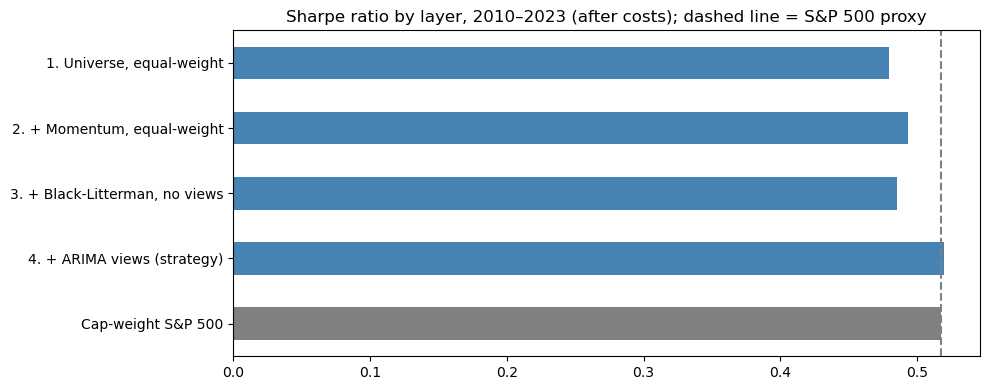

In [19]:
fig, ax = plt.subplots(figsize=(10, 4))
perf_layers["Sharpe"].iloc[::-1].plot(kind="barh", ax=ax, color=["grey"] + ["steelblue"] * 4)
ax.axvline(perf_layers.loc["Cap-weight S&P 500", "Sharpe"], color="grey", ls="--")
ax.set_title("Sharpe ratio by layer, 2010–2023 (after costs); dashed line = S&P 500 proxy")
plt.tight_layout()
plt.show()

## 11. Sensitivity

**Settings.** Each setting is varied one at a time from the baseline, over 2010–2023 after costs. If small changes swing the result widely, the baseline result should not be trusted.

**Costs.** The baseline is re-run at 0, 25 and 50 bps per trade.

**Time.** The 14 years are split into two halves to check that the result is not driven by one period.

In [20]:
VARIANTS = {"Baseline": {}}
VARIANTS.update({f"max_weight = {v:.0%}": {"max_weight": v} for v in (0.10, 0.30, 1.00)})
VARIANTS.update({f"n_select = {v}": {"n_select": v} for v in (15, 35)})
VARIANTS.update({"No RSI filter": {"rsi_max": 101}})
VARIANTS.update({f"tau = {v}": {"tau": v} for v in (0.025, 0.10)})
VARIANTS.update({"Sample covariance": {"cov": "sample"}})

rows = {}
for name, change in VARIANTS.items():
    curve, _ = simulate(strategy(**{**BASE, **change}), long_dates, LONG_END)
    rows[name] = curve
for bps in (0, 25, 50):
    curve, _ = simulate(STRATEGY["Strategy"], long_dates, LONG_END, cost_bps=bps)
    rows[f"Cost = {bps} bps"] = curve
rows["Cap-weight S&P 500"] = curves_long["Cap-weight S&P 500"]

perf_sens = performance(rows)
show_performance(perf_sens[["CAGR", "Volatility", "Sharpe", "Max drawdown", "Turnover / yr", "Excess vs S&P", "IR", "t-stat"]])

,CAGR,Volatility,Sharpe,Max drawdown,Turnover / yr,Excess vs S&P,IR,t-stat
Baseline,12.2%,20.4%,0.52,-33.0%,453.2%,1.6%,0.15,0.58
max_weight = 10%,13.8%,19.6%,0.60,-32.0%,368.5%,2.8%,0.33,1.25
max_weight = 30%,11.9%,21.2%,0.50,-33.6%,494.9%,1.5%,0.13,0.48
max_weight = 100%,13.7%,24.5%,0.53,-33.8%,569.7%,3.8%,0.24,0.89
n_select = 15,14.2%,20.7%,0.60,-33.1%,421.3%,3.4%,0.32,1.19
n_select = 35,12.8%,20.1%,0.55,-36.5%,450.8%,2.1%,0.20,0.76
No RSI filter,12.0%,20.6%,0.51,-32.8%,422.7%,1.4%,0.14,0.53
tau = 0.025,12.2%,20.4%,0.52,-32.9%,453.3%,1.6%,0.15,0.57
tau = 0.1,12.2%,20.4%,0.52,-33.0%,452.9%,1.6%,0.15,0.58
Sample covariance,12.2%,20.5%,0.52,-33.0%,454.0%,1.6%,0.16,0.59


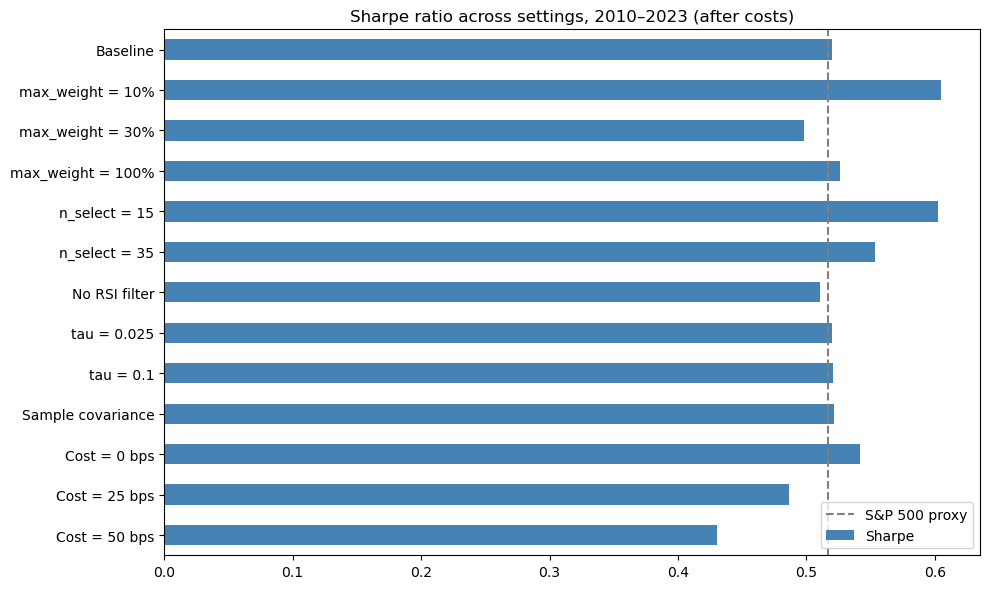

Sharpe across 13 variants: min 0.43, median 0.52, max 0.60 (S&P 500 proxy: 0.52)
Variants beating the S&P 500 proxy's Sharpe: 9 of 13


In [21]:
variants = perf_sens.drop(index="Cap-weight S&P 500")
fig, ax = plt.subplots(figsize=(10, 6))
variants["Sharpe"].iloc[::-1].plot(kind="barh", ax=ax, color="steelblue")
ax.axvline(perf_sens.loc["Cap-weight S&P 500", "Sharpe"], color="grey", ls="--", label="S&P 500 proxy")
ax.set_title("Sharpe ratio across settings, 2010–2023 (after costs)")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Sharpe across {len(variants)} variants: min {variants['Sharpe'].min():.2f}, "
      f"median {variants['Sharpe'].median():.2f}, max {variants['Sharpe'].max():.2f} "
      f"(S&P 500 proxy: {perf_sens.loc['Cap-weight S&P 500', 'Sharpe']:.2f})")
print(f"Variants beating the S&P 500 proxy's Sharpe: {(variants['Sharpe'] > perf_sens.loc['Cap-weight S&P 500', 'Sharpe']).sum()} of {len(variants)}")

In [22]:
halves = {}
for label, (a, b) in {"2010–2016": ("2009-12-31", "2016-12-31"), "2017–2023": ("2016-12-30", "2023-12-31")}.items():
    sliced = {}
    for k, v in curves_long.items():
        s = v.loc[a:b]
        s = s / s.iloc[0]
        s.attrs = v.attrs
        sliced[k] = s
    p = performance(sliced)[["CAGR", "Volatility", "Sharpe", "Max drawdown", "IR"]]
    p.index = pd.MultiIndex.from_product([[label], p.index])
    halves[label] = p
pd.concat(halves.values()).style.format("{:.1%}", subset=["CAGR", "Volatility", "Max drawdown"]).format("{:.2f}", subset=["Sharpe", "IR"])

## 12. Findings

All figures are after 10 bps transaction costs and exclude dividends.

**1. There is no statistically meaningful edge.** Over 2010–2023 the strategy returned 12.2% a year against 11.1% for the S&P 500 proxy, but with more risk (20.4% vs 17.5% volatility). The Sharpe ratio is the same (0.52 vs 0.52), the information ratio is 0.15, and the t-statistic is **0.58**, far below the ~2 needed to rule out luck. The strategy beat the S&P proxy in 8 of 14 years.

**2. The layers add risk, not risk-adjusted return** (section 10):

| Layer | Sharpe | Turnover / yr |
|---|---|---|
| Universe, equal-weight | 0.48 | 67% |
| + Momentum selection | 0.49 | 260% |
| + Black-Litterman (no views) | 0.49 | 242% |
| + ARIMA views | 0.52 | 453% |

Momentum selection and the optimiser each change the Sharpe ratio by about 0.01. The ARIMA views add 0.03 but nearly double the turnover. None of these differences is large enough to be distinguishable from noise.

**3. The results are fairly stable, and consistently unremarkable** (section 11). Across 13 variants the Sharpe ranges from 0.43 to 0.60, against 0.52 for the S&P proxy. The best variants (10% weight cap, or 15 stocks) reach a t-statistic of only about 1.2. Picking the best variant after the fact would be data snooping.

* **τ has no effect.** With the He-Litterman choice $\Omega = \text{diag}(P\,\tau\Sigma\,P^\top)$, τ cancels out of the posterior mean, so only the posterior covariance changes, and only slightly.
* **Ledoit-Wolf vs sample covariance makes no difference** here, because the weight cap already limits how far the optimiser can chase noise.
* **Costs matter.** The return advantage shrinks from 2.0% a year at 0 bps to 0.9% at 25 bps and disappears at about 45 bps. Real-world costs for large caps are usually 5–20 bps.

**4. Both halves of the period agree.** In 2010–2016 the strategy's Sharpe was 0.58 against 0.53 for the S&P proxy; in 2017–2023 it was 0.50 against 0.52. Neither half shows a clear edge.

**5. 2023 was a bad year for the strategy:** 11.5% against 25.7% for the S&P proxy and 37.2% for the cap-weighted top 50. Momentum at the end of 2022 pointed towards energy and defensive stocks, while 2023 was led by mega-cap tech. A one-year result says little on its own (t-statistic −1.2).

**Limitations**
* **Price returns only.** The dataset's dividend field is empty. Absolute returns are understated for every portfolio by roughly the dividend yield (about 2% a year for the S&P 500). How much this changes the *comparison* depends on how the holdings' yields differ from the benchmarks', which this data cannot show.
* **Universe limited to the 50 largest stocks.** Momentum is usually studied across the whole market; among mega-caps, where pricing is most efficient, a weak result is not surprising.
* **Simple cost model.** Costs are linear, with no market impact or bid-ask detail.